# B -> hhh data exploration

This notebook introduces the LHCb open-data sample used in the project and builds the first reconstructed B-candidate mass spectrum. The workflow follows a typical exploratory HEP analysis: inspect the ROOT tree, select relevant branches, apply simple physics-motivated cuts, reconstruct the invariant mass, and extract a first signal estimate.


## Introduction

The decay topology studied here contains a B-meson candidate reconstructed from three charged hadron tracks. The initial analysis uses a charged-kaon mass hypothesis for all daughters, giving a compact demonstration of invariant-mass reconstruction and selection-driven signal enhancement.


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep the matplotlib font cache inside the project so notebook runs stay quiet
# even when the default cache directory is not writable.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "B2HHH_MagnetDown.root"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

DATA_PATH

PosixPath('/Users/yanisidir/Projects/lhcb-b2hhh-analysis/data/raw/B2HHH_MagnetDown.root')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.optimize import curve_fit

from src.reconstruction.invariant_mass import compute_b_mass
from src.plotting.mass_plots import plot_mass_distribution, plot_mass_fit, set_hep_style

set_hep_style()


## Dataset description

The input files are CERN Open Data ROOT ntuples containing reconstructed LHCb B-candidate events. The analysis starts from the `DecayTree` tree in `B2HHH_MagnetDown.root`; the companion MagnetUp and phase-space simulation files can be used for systematic extensions.


In [3]:
root_file = uproot.open(DATA_PATH)
print(root_file.keys())

tree = root_file["DecayTree"]
print(f"Number of events: {tree.num_entries:,}")


['DecayTree;1']
Number of events: 5,135,823


## ROOT tree exploration

Only the branches needed for the first reconstruction are loaded into memory. Momentum components are used to build the invariant mass; PID probabilities and B-candidate quality variables are used for a simple event selection.


In [4]:
available_branches = list(tree.keys())
print(f"Number of branches: {len(available_branches)}")
print(available_branches[:60])


Number of branches: 26
['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_IPChi2', 'H3_isMuon']


In [5]:
BRANCHES = [
    "H1_PX", "H1_PY", "H1_PZ",
    "H2_PX", "H2_PY", "H2_PZ",
    "H3_PX", "H3_PY", "H3_PZ",
    "H1_Charge", "H2_Charge", "H3_Charge",
    "H1_ProbK", "H2_ProbK", "H3_ProbK",
    "H1_ProbPi", "H2_ProbPi", "H3_ProbPi",
    "B_VertexChi2", "B_FlightDistance",
]

df = tree.arrays(BRANCHES, library="pd")
df.head()


,H1_PX,H1_PY,H1_PZ,H2_PX,H2_PY,H2_PZ,H3_PX,H3_PY,H3_PZ,H1_Charge,H2_Charge,H3_Charge,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_VertexChi2,B_FlightDistance
0,375.284205,831.308481,51820.233718,708.073133,-1098.156476,17678.307346,-208.210960,-2586.359121,105848.271681,-1,1,1,0.038616,0.307541,0.193004,0.888755,0.095760,0.138845,1.497280,25.301004
1,-4985.130785,5853.750057,326157.454706,144.300886,85.205300,5324.123346,-175.018535,1325.178792,87681.561846,-1,1,1,0.073556,0.048407,0.080397,0.039064,0.137437,0.758603,1.383338,94.690700
2,-1265.456544,2330.050788,90762.658032,-739.506324,-1036.736792,17885.000646,-1383.996490,-71.081104,85574.929582,1,-1,-1,0.030095,0.000798,0.750751,0.636693,0.986191,0.399602,5.187101,8.284490
3,-720.797259,3413.790588,86793.058768,-381.169232,1081.069786,20276.393591,398.775944,-1134.914464,14653.316611,-1,1,1,0.211414,0.030331,0.005698,0.350969,0.963767,0.964705,7.129099,5.590769
4,397.754571,1791.373059,40040.364159,1841.069628,-794.103213,11610.344506,477.148467,2113.439057,24462.076980,-1,1,1,0.005697,0.012994,0.002979,0.933102,0.886534,0.918983,10.988701,3.013242


In [6]:
df.describe().T[["mean", "std", "min", "max"]]


,mean,std,min,max
H1_PX,-49.205651,2207.446910,-92785.612894,1.698273e+05
H1_PY,41.586797,2107.117576,-124532.725666,4.801947e+05
H1_PZ,49234.250568,54320.585863,1409.112325,1.340168e+07
H2_PX,-11.154879,1015.217906,-26106.723768,4.609276e+04
H2_PY,17.612607,975.406571,-24119.553860,3.037502e+04
H2_PZ,23700.244906,24339.257719,1402.048164,1.277445e+06
H3_PX,-73.979920,3110.653542,-127786.503834,2.787094e+05
H3_PY,63.978163,2950.095446,-313630.317894,2.944744e+05
H3_PZ,76206.500046,64000.977109,1416.576163,1.053143e+07
H1_Charge,-0.016459,0.999865,-1.000000,1.000000e+00


## Event selection

The preselection keeps displaced, well-reconstructed B candidates and tracks compatible with the kaon hypothesis. These cuts are intentionally simple and transparent; a production analysis would optimize them with control samples and systematic studies.


In [7]:
selection_mask = (
    (df["B_VertexChi2"] < 5)
    & (df["B_FlightDistance"] > 20)
    & (df["H1_ProbK"] > 0.5)
    & (df["H2_ProbK"] > 0.5)
    & (df["H3_ProbK"] > 0.5)
)

df_sel = df.loc[selection_mask].copy()
print(f"Candidates before cuts: {len(df):,}")
print(f"Candidates after cuts:  {len(df_sel):,}")
print(f"Selection efficiency:   {len(df_sel) / len(df):.3%}")


Candidates before cuts: 5,135,823
Candidates after cuts:  1,645
Selection efficiency:   0.032%


## Invariant mass reconstruction

The B-candidate mass is computed from the four-vector sum of the three daughter tracks under the kaon mass hypothesis.


In [8]:
df["B_mass"] = compute_b_mass(df)
df_sel["B_mass"] = compute_b_mass(df_sel)

df_sel[["B_mass", "B_VertexChi2", "B_FlightDistance"]].head()


,B_mass,B_VertexChi2,B_FlightDistance
5911,5278.782080,1.044176,53.008846
7561,5280.889118,1.234878,25.028023
8171,5310.000362,1.396345,26.784880
14006,5252.199904,3.868593,21.125746
17076,5299.993524,2.847910,29.216699


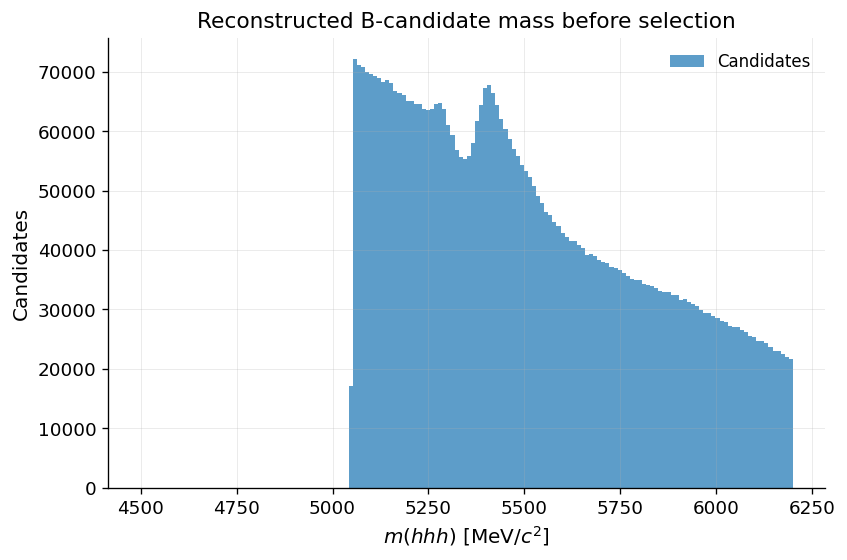

In [9]:
fig, ax = plot_mass_distribution(
    df["B_mass"],
    bins=160,
    mass_range=(4500, 6200),
    title="Reconstructed B-candidate mass before selection",
    output_path=FIGURES_DIR / "B_mass_before_cuts.png",
)
plt.show()


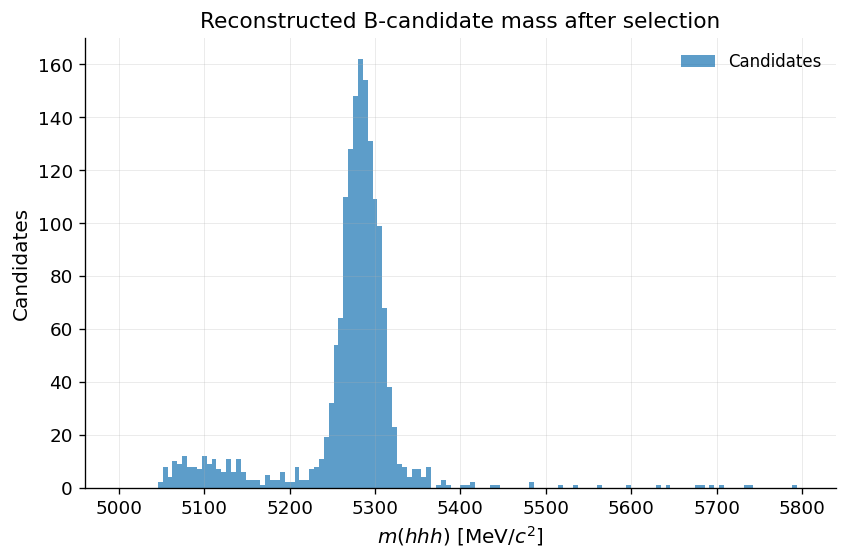

In [10]:
fig, ax = plot_mass_distribution(
    df_sel["B_mass"],
    bins=140,
    mass_range=(5000, 5800),
    title="Reconstructed B-candidate mass after selection",
    output_path=FIGURES_DIR / "B_mass_after_cuts.png",
)
plt.show()


## Signal extraction

A first signal estimate is obtained with a Gaussian peak over a linear combinatorial background in the B-mass region. This is a compact pedagogical model, sufficient for demonstrating the mass peak and motivating later signal/background classification.


In [11]:
def gaussian_plus_linear(x, amplitude, mean, sigma, slope, intercept):
    gaussian = amplitude * np.exp(-0.5 * ((x - mean) / sigma) ** 2)
    background = slope * x + intercept
    return gaussian + background

counts, bin_edges = np.histogram(df_sel["B_mass"], bins=100, range=(5200, 5350))
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

initial_values = [max(counts), 5280, 15, 0, np.median(counts)]
fit_params, covariance = curve_fit(
    gaussian_plus_linear,
    bin_centers,
    counts,
    p0=initial_values,
    maxfev=10000,
)

amplitude, mean, sigma, slope, intercept = fit_params
print(f"Fitted mean:  {mean:.2f} MeV/c^2")
print(f"Fitted sigma: {abs(sigma):.2f} MeV/c^2")


Fitted mean:  5284.23 MeV/c^2
Fitted sigma: 19.59 MeV/c^2


### Superseded by the nominal fit

The Gaussian-plus-linear least-squares fit above is an exploratory first look at
the peak. The nominal signal extraction is an extended binned maximum-likelihood
fit performed with MINUIT over 5200-5600 MeV/c^2,

```bash
python scripts/run_mass_fit.py
```

which returns the yields, uncertainties and fit quality quoted in the report.

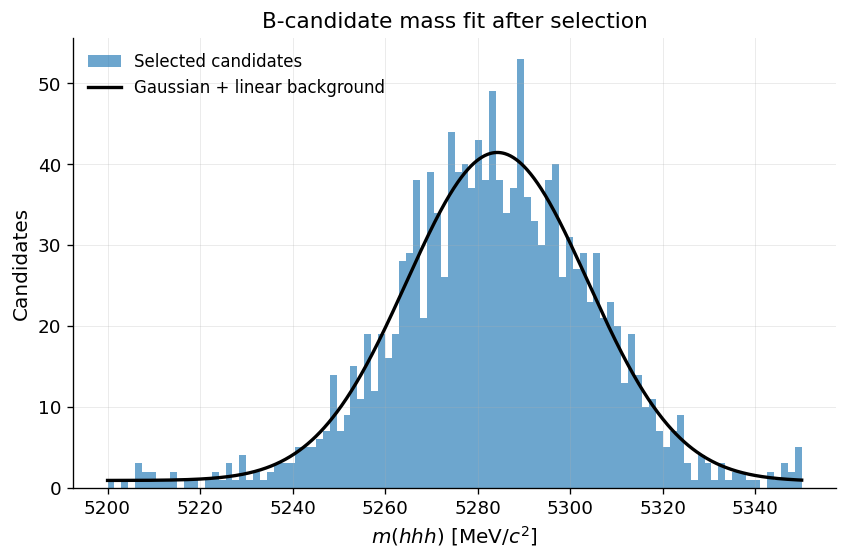

In [12]:
x_fit = np.linspace(5200, 5350, 1000)
y_fit = gaussian_plus_linear(x_fit, *fit_params)

fig, ax = plot_mass_fit(
    df_sel["B_mass"],
    x_fit,
    y_fit,
    bins=100,
    mass_range=(5200, 5350),
    output_path=FIGURES_DIR / "B_mass_fit.png",
)
plt.show()


## Conclusions

The reconstructed mass spectrum shows a clear B-candidate accumulation near the expected B-meson mass after quality and PID selections. The fitted peak position and width provide a useful sanity check of the reconstruction. The next step is to use the signal window and mass sidebands to build labelled samples for a signal/background classifier.
